In [1]:
import numpy as np 
import matplotlib.pyplot as plt

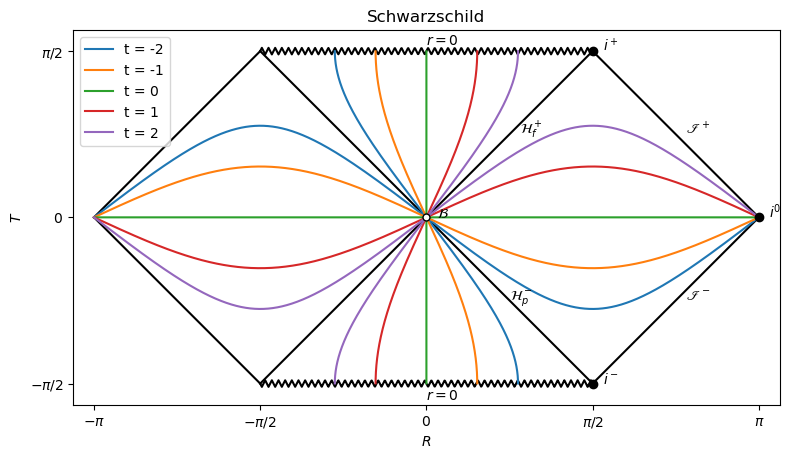

In [2]:


class Penrose_Schwarzschild:
### PRIVATE FUNCTIONS ###
    def _diag_init(self):
        x = np.linspace(-np.pi/2, np.pi/2, 800)

        k = 50

        width = np.pi
        l = width / k
        amp = l / 2 

        s = (x + np.pi/2) / l
        n = np.floor(s).astype(int)
        n = np.minimum(n, k - 1)     # clamp right endpoint
        f = s - n

        f4 = 4 * f
        segment = np.zeros_like(f)
        mask1 = f4 <= 1
        mask2 = (f4 > 1) & (f4 <= 2)
        mask3 = (f4 > 2) & (f4 <= 3)
        mask4 = f4 > 3
        segment[mask1] = amp*f4[mask1]
        segment[mask2] = amp*(2 - f4[mask2])
        segment[mask3] = -amp*(f4[mask3] - 2)
        segment[mask4] = -amp*(4 - f4[mask4])

        y_zigzag = np.pi/2 + segment

        y_zigzag_neg = -np.pi/2 - segment
        plt.figure(figsize=(8, 8))
        # plotting zigzag lines
        plt.plot(x, y_zigzag, lw=1.5, color='black')
        plt.plot(x, y_zigzag_neg, lw=1.5, color='black')

        # line y = x, x€[-pi/2, pi/2]
        x_line = np.array([-np.pi/2, np.pi/2])
        y_line = x_line
        plt.plot(x_line, y_line, lw=1.5, color='black')

        # line y = -x
        y_line2 = -x_line
        plt.plot(x_line, y_line2, lw=1.5, color='black')

        # Scri+ and Scri-
        x_scri = np.array([np.pi/2, np.pi])
        y_scrip = np.pi - x_scri
        y_scrim = -np.pi + x_scri
        plt.plot(x_scri, y_scrip, lw=1.5, color='black')
        plt.plot(x_scri, y_scrim, lw=1.5, color='black')

        # Scri+ left and Scri- left    
        x_scri_l = np.array([-np.pi, -np.pi/2])
        y_scrip_l = np.pi + x_scri_l
        y_scrim_l = -np.pi - x_scri_l
        plt.plot(x_scri_l, y_scrip_l, lw=1.5, color='black')
        plt.plot(x_scri_l, y_scrim_l, lw=1.5, color='black')

        # ensure equal scale on both axes
        ax = plt.gca()
        ax.set_aspect('equal', adjustable='box')

        # set ticks to pi
        ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
        tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']

        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_yticklabels(tick_labels)

        plt.xlim(-np.pi - 0.2, np.pi + 0.2)
        plt.ylim(-np.pi/2 - 0.2, np.pi/2 + 0.2)
        plt.xlabel(r'$R$')
        plt.ylabel(r'$T$')
        plt.title('Schwarzschild')
        plt.tight_layout()

    def _diag_markers(self):
        
        # Dots for  i-, i0, i+
        plt.plot(np.pi/2, np.pi/2, marker='o', color='black')
        plt.plot(np.pi, 0, marker='o', color='black')
        plt.plot(np.pi/2, -np.pi/2, marker='o', color='black')
        

        # Bifurcation sphere
        plt.plot(0, 0, marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, linestyle='None')

        # denoting i-, i0, i+
        plt.text(np.pi/2 + 0.1, -np.pi/2, r'$i^-$')
        plt.text(np.pi + 0.1, 0, r'$i^0$')
        plt.text(np.pi/2 + 0.1, np.pi/2, r'$i^+$')
        # denoting r = 0
        plt.text(0, np.pi/2 + 0.06, r'$r = 0$')
        plt.text(0, -np.pi/2 - 0.15, r'$r = 0$')
        # denoting H+-
        plt.text(np.pi/4 + 0.1, np.pi/4, r'$\mathcal{H}^+_f$')
        plt.text(np.pi/4, -np.pi/4, r'$\mathcal{H}^-_p$')
        # denoting scri
        plt.text(3*np.pi/4 + 0.1, np.pi/4, r'$\mathscr{I}^+$')
        plt.text(3*np.pi/4 + 0.1, -np.pi/4, r'$\mathscr{I}^-$')
        # denoting bifurcation sphere
        plt.text(0 + 0.1, 0, r'$\mathcal{B}$')
    
    region_signs = {
        "I":   (-1, +1),
        "II":  (+1, +1),
        "III": (+1, -1),
        "IV":  (-1, -1),
    }
    # variety of coordinate transformation functions
    def _map_to_penrose(self, U, V):
        U_comp = np.arctan(U)
        V_comp = np.arctan(V)
        T = U_comp + V_comp
        R = -U_comp + V_comp
        return T, R
    
    def _max_extension(self, u, v, regions=["I", "II", "III", "IV"]):
        max_exp = np.log(np.finfo(float).max)


        # Ensuring no overflow
        arg_u = np.minimum(-u/(2*self.rh), max_exp)
        arg_v = np.minimum( v/(2*self.rh), max_exp)

        U_V_of_region = {}

        for reg in regions:
            sU, sV = self.region_signs[reg]
            U = sU*np.exp(arg_u)
            V = sV*np.exp(arg_v)

            # Prevent overflow: compute UV conditions in log space
            sign_UV = sU * sV  # sign of the product
            log_UV_abs = arg_u + arg_v  # log of absolute value

            is_allowed = np.ones_like(U, dtype=bool)

            if reg in ("II", "IV"):
                # for interior regions 0 < UV <= 1
                is_allowed &= (sign_UV > 0)  # UV > 0
                is_allowed &= (log_UV_abs <= 0)  # UV <= 1 means exp(log_UV_abs) <= 1
            if reg in ("I", "III"):
                # exterior regions UV < 0
                is_allowed &= (sign_UV < 0)

            # apply mask
            U_reg = np.where(is_allowed, U, np.nan)
            V_reg = np.where(is_allowed, V, np.nan)

            U_V_of_region[reg] = (U_reg, V_reg)

        return U_V_of_region

    def _r_star_of_r(self, r):
        r_star = np.full_like(r, np.nan)
        mask = r > self.rh

        eps = 1e-300
        x_safe = np.maximum(r[mask]/self.rh - 1, eps)

        r_star[mask] = r[mask] + self.rh * np.log(x_safe)
        return r_star


    def _u_v_of_t_r_star(self, t, r_star):
        u = t - r_star
        v = t + r_star
        return u, v
    



    # Helper functions
    def _add_to_show(self, T, R, color=None, label=None):
        # ensuring safe adding to show list
        self.to_show.append([T, R, color, label])
        
    def _min_gauge_height(self, r, lamb=None):  
        if lamb == None:
            lamb = self.rh
        arg1 = np.abs(r/self.rh - 1)
        arg2 = r/self.rh

        log1 = np.full_like(r, -np.inf)
        log2 = np.full_like(r, -np.inf)
        thresh = np.exp(np.finfo(float).min)
        mask1 = arg1 > thresh
        mask2 = arg2 > thresh

        log1[mask1] = np.log(arg1[mask1])
        log2[mask2] = np.log(arg2[mask2])

        return (self.rh*log1 - 2*self.rh*log2 - r)/lamb

###-----------------------###
##-------------------------##
#---OBJECT INITIALIZATION---#
##-------------------------##
###-----------------------###
    def __init__(self, rh=1):
        self.rh = rh
        self.to_show = []
        self.color_cycle = iter(plt.rcParams['axes.prop_cycle'].by_key()['color'])

#---------------------------#
### PUBLIC FUNCTIONS ###
    def add_T_R_curve(self, T, R, color=None, label=None):
        self._add_to_show(T, R, color=color, label=label)
    
    def add_U_V_curve(self, U, V, color=None, label=None):
        T, R = self._map_to_penrose(U, V)
        self._add_to_show(T, R, color=color, label=label)
        
    def add_u_v_curve(self, u, v, color=None, label=None):
        U_V_of_region = self._max_extension(u, v)
        
        first_iter = True
        for (U, V) in U_V_of_region.values():
            T, R = self._map_to_penrose(U, V)
            if color is None: 
                try:
                    color = next(self.color_cycle)
                except StopIteration:
                    self.color_cycle = iter(plt.rcParams['axes.prop_cycle'].by_key()['color'])
                    color = next(self.color_cycle)
            if not first_iter:
                label = None
            first_iter = False
            self._add_to_show(T, R, color, label) 
    
    def add_t_r_curve(self, t, r, color=None, label=None):
        r_star = self._r_star_of_r(r)
        u, v = self._u_v_of_t_r_star(t, r_star)
        self.add_u_v_curve(u, v, color, label)

    def add_tau_sigma_curve(self, tau, sigma, lamb=None, color=None, label=None):
        if lamb == None:
            lamb = self.rh
        r = self.rh/sigma

        t = lamb*(tau - self._min_gauge_height(r, lamb))
        self.add_t_r_curve(t, r, color=color, label=label)




    def show(self):
        self._diag_init()
        for T, R, cl, label in self.to_show:
            if cl != None and label != None:
                plt.plot(R, T, color=cl, label=label)
            elif cl != None:
                plt.plot(R, T, color=cl)
            elif label != None:
                plt.plot(R, T, label=label)
            else:
                plt.plot(R, T)
        self._diag_markers()
        # show legend only if any non-empty label present
        if any((lbl is not None and lbl != '') for _, _, _, lbl in self.to_show):
            plt.legend()
        plt.show()

diag = Penrose_Schwarzschild(rh=1)

u = np.linspace(-50,50,1001)
v = np.tanh(u)
t_vals = np.arange(-2, 3, 1)
r = np.linspace(0, 25, 20000)

for i, val in enumerate(t_vals):
    t = val*np.ones_like(r)
    diag.add_t_r_curve(t, r, label=fr"t = {val}")


diag.show()


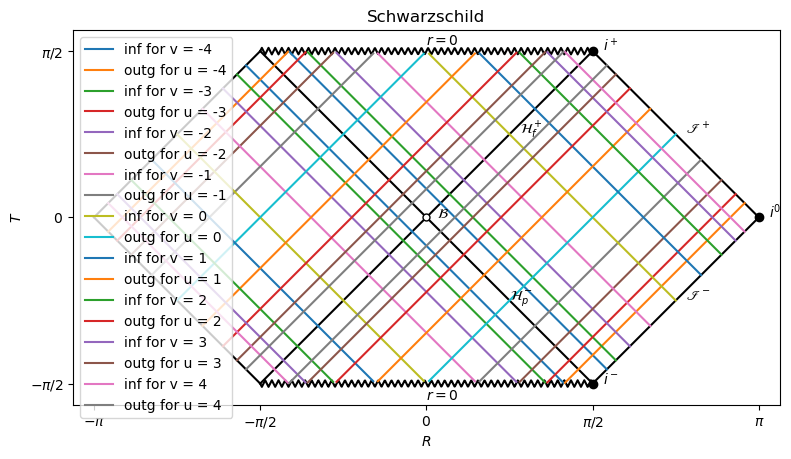

In [3]:
vals = np.arange(-4, 5, 1)
u_inf = np.linspace(-100, 100, 1000)


v_outg = np.linspace(-100, 100, 1000)
u_outg = 0*np.ones_like(v_outg)
diag = Penrose_Schwarzschild(rh=1)
for val in vals:
    v_inf = val*np.ones_like(u_inf)
    u_outg = val*np.ones_like(v_outg)
    diag.add_u_v_curve(u_inf, v_inf, label=f"inf for v = {val}")
    diag.add_u_v_curve(u_outg, v_outg, label=f"outg for u = {val}")




diag.show()

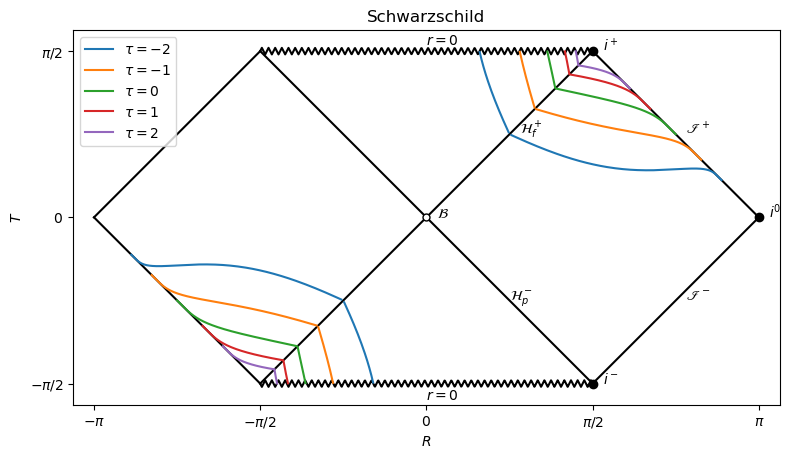

In [4]:
sigma_i = 10**(-6)
taus_values = np.arange(-2, 3, 1)
sigma = np.linspace(sigma_i, 50, 10000)
rh = 1
diag = Penrose_Schwarzschild(rh=rh)

for val in taus_values:
    tau = val*np.ones_like(sigma)
    diag.add_tau_sigma_curve(tau, sigma, label=rf"$\tau = {val}$")

diag.show()